# **Final Year Project - Year 4 Software Development**
## Iteration 1 - Onset Detection Research
*By Mark Lambert - C00192497*
*17/10/2026*
---

The following notebook is a follow-along with [librosa.org's](https://librosa.org/doc/dev/auto_tutorials/01-intro/05-onsets.html) tutorial on onset detection.

My goal for this notebook is to follow along with the code process of extracting onset frames from an audio clip. 

The clip used for this was recorded on an electric guitar.

```%pip install matplotlib librosa sounddevice```

In [1]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio
import soundfile as sf

# Load the audio
cToG, sr = librosa.load('clips/sample/all_chords.wav', sr=None)

C:\Users\markl\pipx\venvs\jupyterlab\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Displays a plot of the Short-time Fourier Transform of the clip

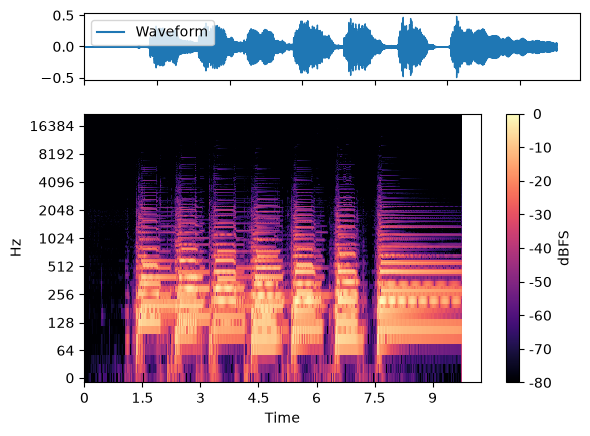

In [2]:
S = librosa.stft(cToG)

# Generate a plot of waveform and spectrogram
fig, ax = plt.subplots(nrows=2, sharex=True, height_ratios=(1, 4))
librosa.display.waveshow(y=cToG, sr=sr, ax=ax[0], label="Waveform")
img = librosa.display.specshow(S, vscale="dBFS", x_axis="time", y_axis="log", sr=sr)
librosa.display.colorbar_db(img, label="dBFS")
ax[0].label_outer()
ax[0].legend()

In [3]:
# Map the magnitude abs(S) to decibels
logS = librosa.amplitude_to_db(np.abs(S), ref=np.max)

# Compute the first-order difference logS[:, t] - logS[:, t-1]
# along the time direction.
# We'll pad the differencing operation with the first column of
# logS to prevent a spike in the first step.
# This also ensures that the output has the same number of frames as the
# input (`logS`), since the differencing operation would otherwise
# discard the first frame.
diffS = np.diff(logS, axis=-1, prepend=logS[:, :1])

# We'll threshold out any negative values as these correspond to
# falling energy
diffS_thresh = np.maximum(diffS, 0)

# Average across frequencies to get the onset strength envelope
onset_env = np.mean(diffS_thresh, axis=0)

times = librosa.times_like(onset_env, sr=sr)

Marks every peak in the onset evelope with a triangle, but every single bump gets counted

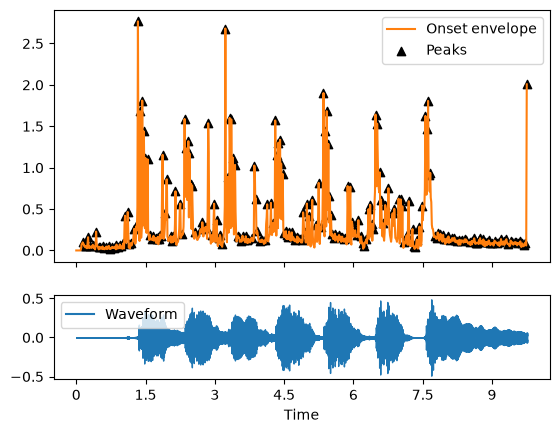

In [4]:
onset_peaks = librosa.util.localmax(onset_env)

fig, ax = plt.subplots(nrows=2, sharex=True, height_ratios=(3, 1))

librosa.display.waveshow(y=cToG, sr=sr, ax=ax[1], label="Waveform")
ax[1].legend()
ax[0].plot(times, onset_env, label="Onset envelope", color="C1")
ax[0].scatter(times[onset_peaks], onset_env[onset_peaks], marker="^", color="k", label="Peaks")
ax[0].legend()
ax[0].label_outer()

Applies more strict rules to the peaks, so more intense peaks are highlighted by a green circle.

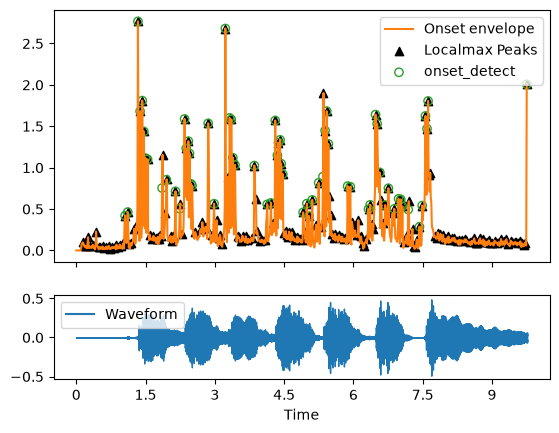

In [5]:
onset_detect = librosa.onset.onset_detect(onset_envelope=onset_env)

fig, ax = plt.subplots(nrows=2, sharex=True, height_ratios=(3, 1))

librosa.display.waveshow(y=cToG, sr=sr, ax=ax[1], label="Waveform")
ax[1].legend()
ax[0].plot(times, onset_env, label="Onset envelope", color="C1")
ax[0].scatter(times[onset_peaks], onset_env[onset_peaks], marker="^", color="k", label="Localmax Peaks")
ax[0].scatter(times[onset_detect], onset_env[onset_detect], marker="o",
              edgecolor="C2", facecolor="none", label="onset_detect")
ax[0].legend()
ax[0].label_outer()

A click track can be overlayed onto the clip where each click is a peak detected in the audio

In [6]:
# Generate a click track from the detected frames
# and match the length to the original input signal
clicks = librosa.clicks(frames=onset_detect, length=len(cToG), sr=sr)

# Sonify the result
Audio(data=cToG + clicks, rate=sr)

In [12]:
sf.write('clips/C_to_G_clicks.wav', cToG + clicks, sr)

## Findings

- `onset_detect` returns several onsets per strum, plus a few extra onsets that may be due to string buzz and noise
- Next step: group the onsets that belong to the same strum, then classify the chord for each group